In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings('ignore')

# Step 1: Exploratory Data Analyisis

In [2]:
df = pd.read_csv('csv_files/heart.csv')

In [3]:
df.shape

(918, 12)

In [4]:
df.info() 

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 97.6 KB


In [5]:
df.duplicated().sum()

np.int64(0)

## First we start by exploring numerical coloumns

<Axes: xlabel='HeartDisease'>

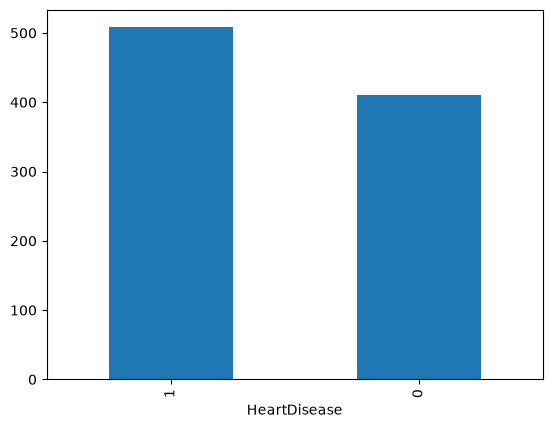

In [6]:
df['HeartDisease'].value_counts().plot(kind='bar')

In [7]:
df.isnull().sum()

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

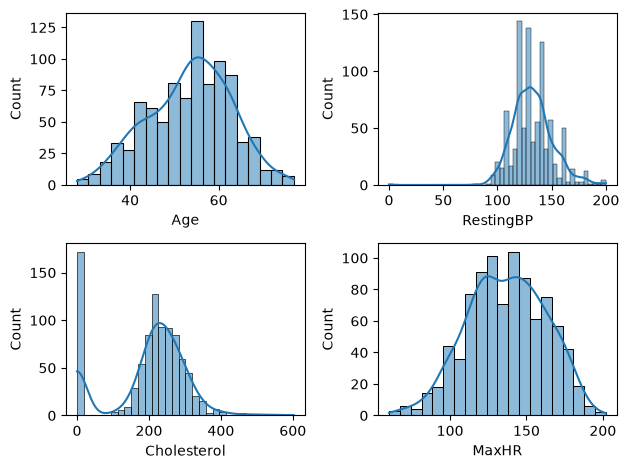

In [8]:
def plotting(var, num):
    plt.subplot(2,2, num)
    sns.histplot(df[var], kde=True)

plotting("Age", 1)

plotting("RestingBP", 2)

plotting("Cholesterol", 3)

plotting("MaxHR", 4)

plt.tight_layout()

  ### we can see theres incorrect data in cholestrol and resting bp thus we will clean them. there are lot of 0s in those coloumns

In [21]:
df[df['Cholesterol'] == 0]

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
293,65,M,ASY,115,0,0,Normal,93,Y,0.0,Flat,1
294,32,M,TA,95,0,1,Normal,127,N,0.7,Up,1
295,61,M,ASY,105,0,1,Normal,110,Y,1.5,Up,1
296,50,M,ASY,145,0,1,Normal,139,Y,0.7,Flat,1
297,57,M,ASY,110,0,1,ST,131,Y,1.4,Up,1
...,...,...,...,...,...,...,...,...,...,...,...,...
514,43,M,ASY,122,0,0,Normal,120,N,0.5,Up,1
515,63,M,NAP,130,0,1,ST,160,N,3.0,Flat,0
518,48,M,NAP,102,0,1,ST,110,Y,1.0,Down,1
535,56,M,ASY,130,0,0,LVH,122,Y,1.0,Flat,1


### we see theres 172 rows with 0 cholesterol. so we will take mean of remaining rows and fill the rows with 0s.

In [35]:
mean_cholestrol = df[df["Cholesterol"] != 0]['Cholesterol'].mean().round(2)
mean_cholestrol

np.float64(244.64)

In [41]:
df['Cholesterol'] = df['Cholesterol'].replace(0, mean_cholestrol)
df["Cholesterol"].value_counts()

Cholesterol
244.64    171
254.00     11
223.00     10
220.00     10
211.00      9
         ... 
353.00      1
278.00      1
157.00      1
176.00      1
131.00      1
Name: count, Length: 222, dtype: int64

### now the 171 rows are filled with the mean value.

In [37]:
df[df['RestingBP'] == 0]

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease


### and theres one row with 0 restingBP. we can either take mean of remaining rows or drop this. I'm choosing to drop this row.

In [38]:
# Drop rows where RestingBP is 0 using their index
df = df.drop(df[df['RestingBP'] == 0].index)


In [39]:
df[df['RestingBP'] == 0] # now theres 0 rows with 0 values

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease


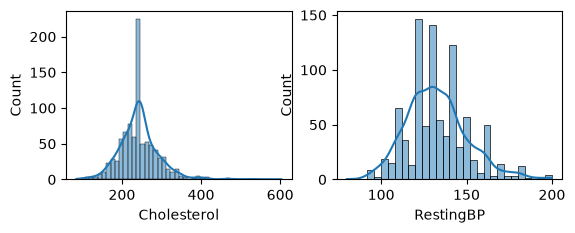

In [42]:
plotting("Cholesterol", 1)
plotting("RestingBP", 2)

## now we start exploring and analysing categorical coloumns

<Axes: xlabel='Sex', ylabel='count'>

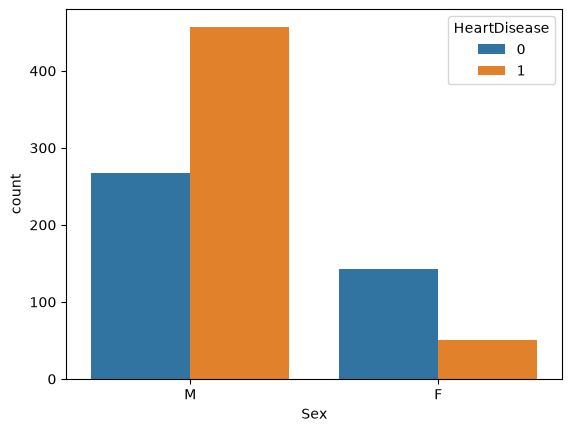

In [47]:
sns.countplot(x= df['Sex'], hue=df['HeartDisease'])

<Axes: xlabel='ChestPainType', ylabel='count'>

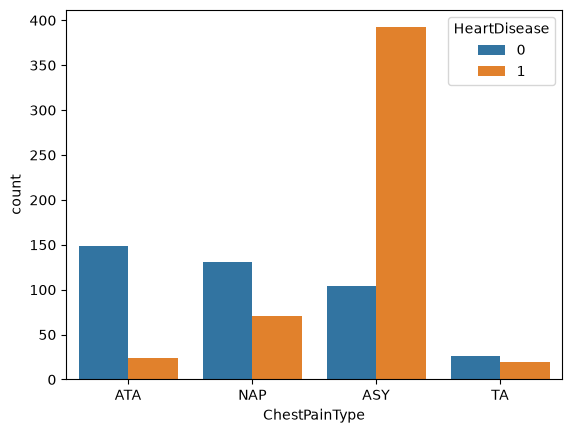

In [49]:
sns.countplot(x= df['ChestPainType'], hue=df['HeartDisease'])

<Axes: xlabel='FastingBS', ylabel='count'>

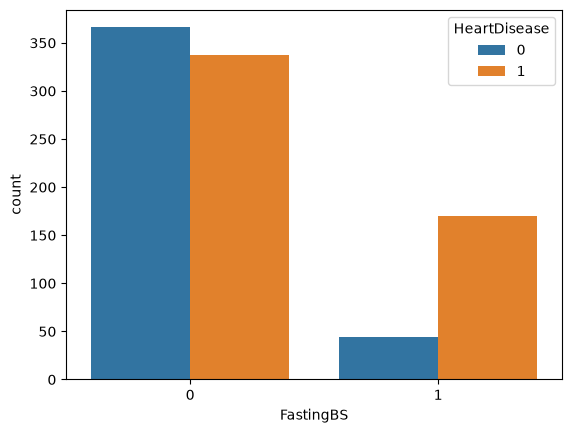

In [50]:
sns.countplot(x= df['FastingBS'], hue=df['HeartDisease'])

### in order to compare a categorical coloumn and numeric coloumn, we use blox plot

<Axes: xlabel='HeartDisease', ylabel='Cholesterol'>

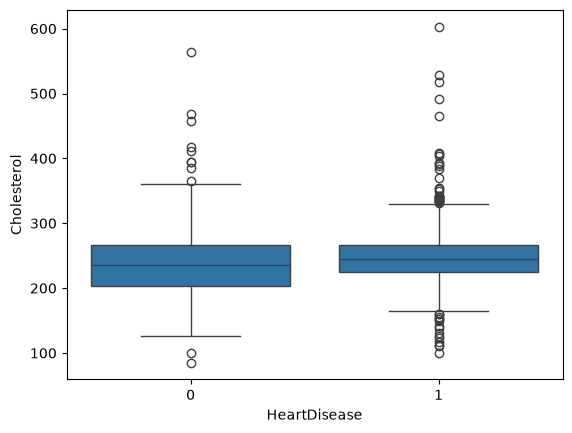

In [52]:
sns.boxplot(y = df['Cholesterol'], x = df['HeartDisease'])

<Axes: xlabel='HeartDisease', ylabel='Age'>

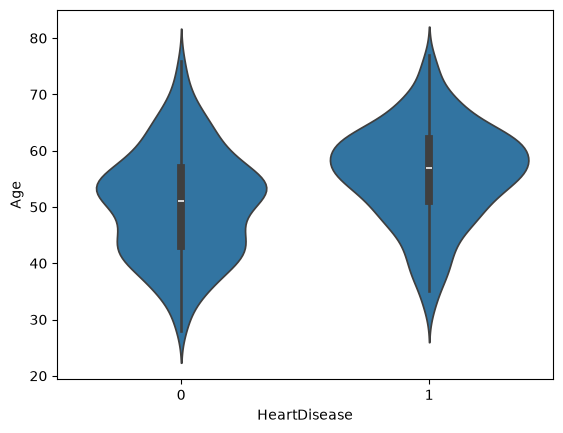

In [54]:
sns.violinplot(y = df['Age'], x = df['HeartDisease'])

<function matplotlib.pyplot.tight_layout(*, pad: 'float' = 1.08, h_pad: 'float | None' = None, w_pad: 'float | None' = None, rect: 'tuple[float, float, float, float] | None' = None) -> 'None'>

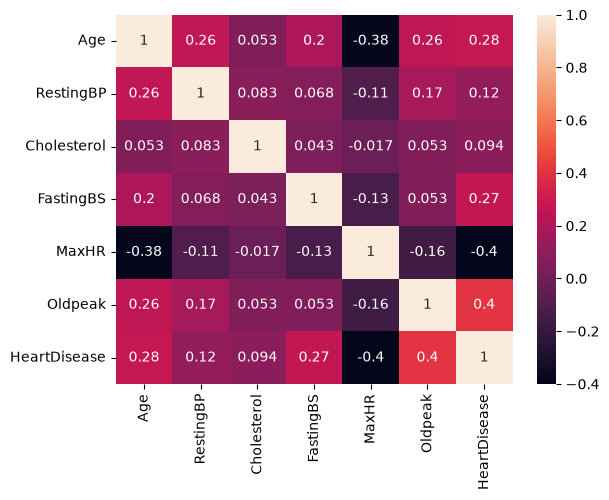

In [56]:
sns.heatmap(df.corr(numeric_only=True), annot=True)
plt.tight_layout

In [57]:
df.head(5)

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289.0,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180.0,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283.0,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214.0,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195.0,0,Normal,122,N,0.0,Up,0


In [63]:
from scipy.stats import chi2_contingency

In [64]:
alpha = 0.5
cat_features = ['Sex', 'ChestPainType', 'FastingBS',
       'RestingECG', 'ExerciseAngina', 'ST_Slope']
def perform_chi2_test(df: pd.DataFrame, cat_features: list[str], target_col: str, alpha: float = 0.05) -> dict:
    """
    Perform Chi-square test of independence for categorical features against a target variable.
    
    Args:
        df: DataFrame containing the data
        cat_features: List of categorical feature column names to test
        target_col: Name of the target column (e.g., 'charges_bin')
        alpha: Significance level for hypothesis testing (default: 0.05)
    
    Returns:
        Dictionary containing chi-square statistics, p-values, and decisions for each feature
    """
    chi2_results = {}
    
    for col in cat_features:
        # Create contingency table
        contingency = pd.crosstab(df[col], df[target_col])
        
        # Perform chi-square test
        chi2_stat, p_val, _, _ = chi2_contingency(contingency)
        
        # Make decision based on p-value
        decision = "Reject Null (keep feature)" if p_val < alpha else "Accept Null (drop feature)"
        
        chi2_results[col] = {
            'chi2_statistic': chi2_stat,
            'p_value': p_val,
            'decision': decision
        }
    
    return chi2_results

# Usage
chi2_results = perform_chi2_test(df, cat_features, 'HeartDisease', alpha=alpha)

chi2_df = pd.DataFrame(chi2_results).T.sort_values(by='p_value')
chi2_df

,chi2_statistic,p_value,decision
ST_Slope,355.155699,0.0,Reject Null (keep feature)
ChestPainType,268.896258,0.0,Reject Null (keep feature)
ExerciseAngina,223.107207,0.0,Reject Null (keep feature)
Sex,83.871151,0.0,Reject Null (keep feature)
FastingBS,64.591342,0.0,Reject Null (keep feature)
RestingECG,11.069537,0.003947,Reject Null (keep feature)


## Step 2: DataPreprocessing

In [98]:
df_encode = df.copy()

In [99]:
df_encode = pd.get_dummies(df_encode, columns = ["Sex"] ,drop_first=True)
df_encode = pd.get_dummies(df_encode, drop_first=False)
df_encode.astype(int)

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_M,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST,ExerciseAngina_N,ExerciseAngina_Y,ST_Slope_Down,ST_Slope_Flat,ST_Slope_Up
0,40,140,289,0,172,0,0,1,0,1,0,0,0,1,0,1,0,0,0,1
1,49,160,180,0,156,1,1,0,0,0,1,0,0,1,0,1,0,0,1,0
2,37,130,283,0,98,0,0,1,0,1,0,0,0,0,1,1,0,0,0,1
3,48,138,214,0,108,1,1,0,1,0,0,0,0,1,0,0,1,0,1,0
4,54,150,195,0,122,0,0,1,0,0,1,0,0,1,0,1,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,110,264,0,132,1,1,1,0,0,0,1,0,1,0,1,0,0,1,0
914,68,144,193,1,141,3,1,1,1,0,0,0,0,1,0,1,0,0,1,0
915,57,130,131,0,115,1,1,1,1,0,0,0,0,1,0,0,1,0,1,0
916,57,130,236,0,174,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0


In [104]:
df_encode.columns

Index(['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak',
       'HeartDisease', 'Sex_M', 'ChestPainType_ASY', 'ChestPainType_ATA',
       'ChestPainType_NAP', 'ChestPainType_TA', 'RestingECG_LVH',
       'RestingECG_Normal', 'RestingECG_ST', 'ExerciseAngina_N',
       'ExerciseAngina_Y', 'ST_Slope_Down', 'ST_Slope_Flat', 'ST_Slope_Up'],
      dtype='str')

In [105]:
from sklearn.preprocessing import StandardScaler

In [110]:
scaler = StandardScaler()

numeric_columns = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak' ]

In [111]:
df_encode[numeric_columns] = scaler.fit_transform(df_encode[numeric_columns])
df_encode.head()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_M,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST,ExerciseAngina_N,ExerciseAngina_Y,ST_Slope_Down,ST_Slope_Flat,ST_Slope_Up
0,-1.432206,0.414627,0.832059,0,1.383339,-0.831502,0,True,False,True,False,False,False,True,False,True,False,False,False,True
1,-0.478057,1.526360,-1.212278,0,0.754736,0.106251,1,False,False,False,True,False,False,True,False,True,False,False,True,False
2,-1.750256,-0.141240,0.719527,0,-1.523953,-0.831502,0,True,False,True,False,False,False,False,True,True,False,False,False,True
3,-0.584074,0.303453,-0.574595,0,-1.131075,0.575128,1,False,True,False,False,False,False,True,False,False,True,False,True,False
4,0.052026,0.970493,-0.930947,0,-0.581047,-0.831502,0,True,False,False,True,False,False,True,False,True,False,False,False,True
